**1. Importing all the required libraries.**

In [1]:
import pandas as pd # importing pandas library
import numpy as np  # here importing numpy
import matplotlib.pyplot as plt # impoting matplotlib for plotting chart
from sklearn.datasets import load_breast_cancer  # importing load_breast_cancer dataset from sklearn.datasets
from sklearn.model_selection import train_test_split # importing train_test_split for splitting dataset into training and testing data
from sklearn.preprocessing import StandardScaler # importing StandardScaler for feature scaling of data
from sklearn.neural_network import MLPClassifier # here importing MLPClassifier
from sklearn.svm import SVC # here importing SVC
from sklearn.tree import DecisionTreeClassifier # here importing DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,accuracy_score, precision_score, recall_score, f1_score) # importing all required metrics from sklearn

**2. Dataset:**

Using the Breast Cancer Wisconsin (Diagnostic) dataset: 569 observations, 30 numeric predictors, and two classes (malignant and benign). For this assignment as instructed I am considering, encode malignant = 1 (positive) and benign = 0 (negative).

In [2]:
# Loading the dataset
data = load_breast_cancer()

# Extracting the 30 numeric predictors
X = data.data

# considering Encode malignant = 1 and benign = 0 as per instruction
y = (data.target == 0).astype(int)

print("Dataset shape:", X.shape) # checking shape of dataset
print("Number of observations:", X.shape[0]) # checking number of observation of dataset
print("Number of features:", X.shape[1]) # checking number of features of dataset
print("Malignant cases:", sum(y == 1)) # checking Malignant cases of dataset
print("Benign cases:", sum(y == 0)) # checking Benign cases of dataset


Dataset shape: (569, 30)
Number of observations: 569
Number of features: 30
Malignant cases: 212
Benign cases: 357


**3. Experimental Design:** Splitting dataset and using StandardScaler for scaling.

In [3]:
# Spliting dataset for training and testing using 80 and 20 strategy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler() # using StandardScaler for feature scaling
X_train_scaled = scaler.fit_transform(X_train) # fitting training data
X_test_scaled = scaler.transform(X_test) # fitting testing data

•	Fit StandardScaler on training data only; transform training and test data for ANN and SVM.

•	Train a Decision Tree on unscaled numerical features.

In [4]:
ann = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu',solver='adam', max_iter=2000, random_state=42) # Importing ANN model that learns using backpropagation(2 hidden layer, relu activation function, adam optmizer, 2000 maximum iteration and 42 randon state)
svm = SVC(kernel='rbf', C=1.0, random_state=42) # here initializing Support Vector Machine classification model
tree = DecisionTreeClassifier(criterion='gini', random_state=42) # here initializing Decision Tree classification model

ann.fit(X_train_scaled, y_train) # here training ANN model using scaled training features and training labels
svm.fit(X_train_scaled, y_train) # here training SVM model using scaled training features and training labels
tree.fit(X_train, y_train) # here training Decision Tree using the original, unscaled training features

ann_pred = ann.predict(X_test_scaled) # here predicting classes of test observations using the trained ANN model
svm_pred = svm.predict(X_test_scaled) # here predicting classes of test observations using the trained SVM model
tree_pred = tree.predict(X_test) # here predicting classes of test observations using the trained Decision Tree

•	Use identical test examples for all three models; do not tune hyperparameters on the test set.

•	Label confusion matrices with actual classes on rows and predicted classes on columns.

    -Plot all three confusion matrices with labels [0, 1].

    -Extract TN, FP, FN, TP and compute specificity.

    -Compute accuracy.

    -Prepare comparison table.

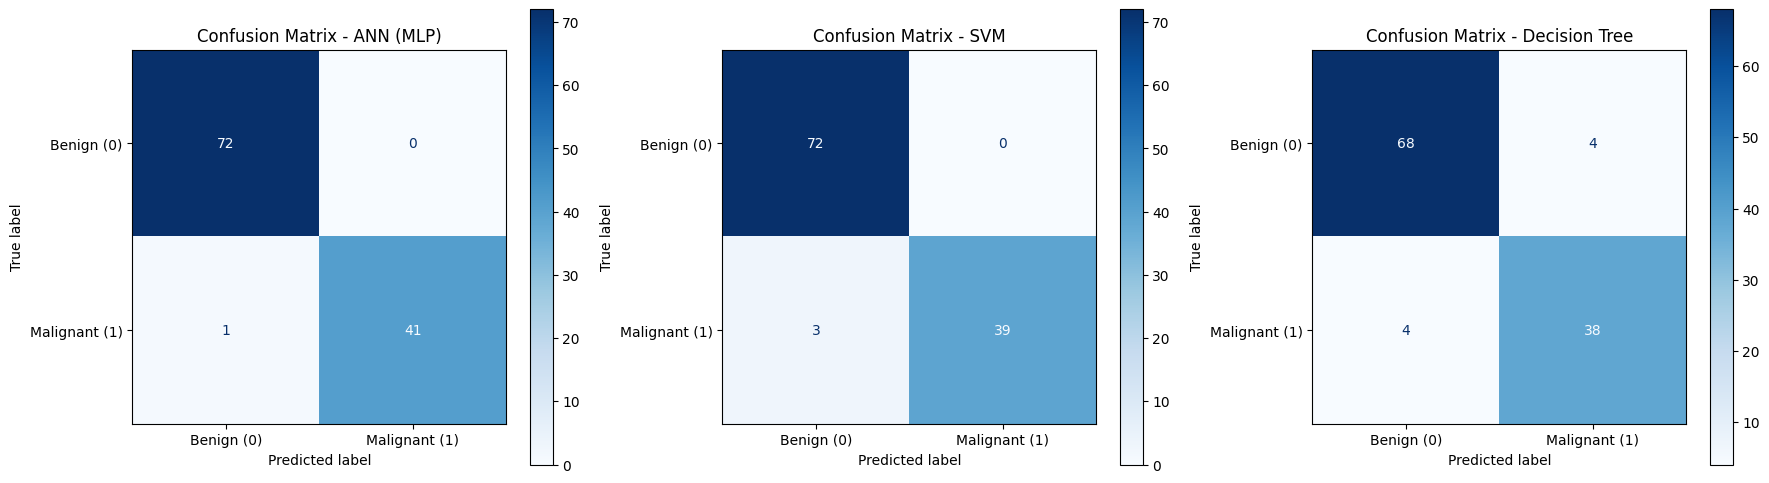


--- Model Comparison Table ---
        Model  Accuracy  Precision  Specificity  Sensitivity (Recall)  TP  TN  FP  FN
    ANN (MLP)  0.991228   1.000000     1.000000              0.976190  41  72   0   1
          SVM  0.973684   1.000000     1.000000              0.928571  39  72   0   3
Decision Tree  0.929825   0.904762     0.944444              0.904762  38  68   4   4


In [5]:
# here i am defining predictions and model names
predictions = {'ANN (MLP)': ann_pred,'SVM': svm_pred,'Decision Tree': tree_pred}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
results = []

for i, (name, pred) in enumerate(predictions.items()):
    # Plotting confusion matrix
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign (0)", "Malignant (1)"]) # Displaying class labels: benign = 0 and malignant = 1
    disp.plot(ax=axes[i], cmap=plt.cm.Blues, values_format='d')
    axes[i].set_title(f'Confusion Matrix - {name}')

    # Extracting TN, FP, FN, TP
    tn, fp, fn, tp = cm.ravel()

    # Computing metrics
    accuracy = accuracy_score(y_test, pred)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0 # recall
    precision = precision_score(y_test, pred, zero_division=0)

    # Adding all the computed metrics to the comparison dictionary
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Specificity': specificity,
        'Sensitivity (Recall)': sensitivity,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn
    })

plt.tight_layout()
plt.show()

# Preparing and displaying the comparison table
comparison_df = pd.DataFrame(results)
print("\n--- Model Comparison Table ---")
print(comparison_df.to_string(index=False))

**Results:**

From the test output, ANN model came out to be the most accurate having achieved 99.12% accuracy, then SVM with 97.37%, and finally Decision Tree with 92.98% accuracy. ANN model classified 113 out of 114 test cases correctly, with only 1 false negative case. SVM has 3 false negatives, and Decision Tree has 4 false positives and 4 false negatives. Generally, ANN came out to be the best model in terms of accuracy, precision, specificity, and sensitivity for this test split.